In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import shutil
import random
from pathlib import Path
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import copy
import os
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from PIL import Image  # Import PIL to resize images
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
import torch.optim as optim
from torch.optim import lr_scheduler

In [2]:
#Setup Path
FILTERED_DIR = r"C:\Users\adria\Desktop\Msx Project\Coding\2nd dataset"  # Replace with actual dataset path
AUGMENTED_DIR = os.path.join(FILTERED_DIR, "augmented")
SPLITS = ["train", "val", "test"]
RATIO = {"train": 0.8, "val": 0.1, "test": 0.1}
BATCH_SIZE = 8
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")


In [4]:
#Ensure necessary directories
for split in SPLITS:
    for label in ["PASS", "REJECT"]:
        os.makedirs(os.path.join(AUGMENTED_DIR, split, label), exist_ok=True)

In [7]:
#Ensure necessary directories
for split in SPLITS:
    for label in ["PASS", "REJECT"]:
        os.makedirs(os.path.join(AUGMENTED_DIR, split, label), exist_ok=True)

#Data Augmentation with New Transformations
transformations = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.RandomPerspective(distortion_scale=0.5, p=0.5),
    transforms.Resize((224, 224))
])

for label in ["PASS", "REJECT"]:
    label_dir = os.path.join(FILTERED_DIR, label)
    augmented_label_dir = os.path.join(AUGMENTED_DIR, "all", label)
    os.makedirs(augmented_label_dir, exist_ok=True)

    for image_name in os.listdir(label_dir):
        image_path = os.path.join(label_dir, image_name)
        image = Image.open(image_path).convert("RGB")

        for i in range(8):  # Augment to get 8x data
            augmented_image = transformations(image)
            augmented_image.save(os.path.join(augmented_label_dir, f"{Path(image_name).stem}_aug{i}.jpg"))

In [9]:
#Split Dataset
for label in ["PASS", "REJECT"]:
    augmented_label_dir = os.path.join(AUGMENTED_DIR, "all", label)
    images = [os.path.join(augmented_label_dir, img) for img in os.listdir(augmented_label_dir)]

    train, test_val = train_test_split(images, test_size=(1 - RATIO["train"]))
    val, test = train_test_split(test_val, test_size=(RATIO["test"] / (RATIO["val"] + RATIO["test"])))

    for split, split_images in zip(SPLITS, [train, val, test]):
        split_dir = os.path.join(AUGMENTED_DIR, split, label)
        for img_path in split_images:
            shutil.copy(img_path, split_dir)

In [3]:
#Load Data and Label It
class CustomDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_paths = []
        self.labels = []

        for label, folder in enumerate(["PASS", "REJECT"]):
            folder_path = os.path.join(root_dir, folder)
            for img_name in os.listdir(folder_path):
                self.image_paths.append(os.path.join(folder_path, img_name))
                self.labels.append(label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

#Prepare Data Loaders
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_dataset = CustomDataset(root_dir=os.path.join(AUGMENTED_DIR, "train"), transform=transform)
val_dataset = CustomDataset(root_dir=os.path.join(AUGMENTED_DIR, "val"), transform=transform)
test_dataset = CustomDataset(root_dir=os.path.join(AUGMENTED_DIR, "test"), transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [4]:
#Load and Fine-Tune ResNet101
Resnet101 = models.resnet101(pretrained=True)
print(Resnet101)
#Set requires_grad to True for all layers to match the script provided
for param in Resnet101.parameters():
    param.requires_grad = True

#Replace the final fully connected layer
num_features = Resnet101.fc.in_features
Resnet101.fc = nn.Linear(num_features, 2)  # 2 classes: PASS and REJECT
Resnet101 = Resnet101.to(DEVICE)

c:\Users\adria\.conda\envs\deeplearning\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\adria\.conda\envs\deeplearning\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [5]:
#Define optimizer, loss function, and learning rate scheduler to match the provided script
optimizer = optim.Adam(Resnet101.parameters(), lr=0.00001)
scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
loss_function = nn.CrossEntropyLoss()

#Training function
def train_model(model, dataloaders, criterion, optimizer, scheduler, num_epochs=25):
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []

    for epoch in range(num_epochs):
        print(f"Epoch {epoch}/{num_epochs - 1}")
        print("-" * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(DEVICE)
                labels = labels.to(DEVICE)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)

            print(f"{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")
            print()

            if phase == 'train':
                train_losses.append(epoch_loss)
                train_accuracies.append(epoch_acc.item())
            else:
                val_losses.append(epoch_loss)
                val_accuracies.append(epoch_acc.item())

    #Plot the training and validation performance
    epochs = range(num_epochs)
    plt.figure(figsize=(12, 5))

        # Training plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, label='Train Loss')
    plt.plot(epochs, train_accuracies, label='Train Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Value')
    plt.title('Training Performance')
    plt.legend()

    # Validation plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Value')
    plt.title('Validation Performance')
    plt.legend()

    plt.show()
    return model

Using GPU for training.
Epoch 0/24
----------
train Loss: 0.4212 Acc: 0.8014

val Loss: 0.2630 Acc: 0.8784

Epoch 1/24
----------
train Loss: 0.2174 Acc: 0.9136

val Loss: 0.2489 Acc: 0.9072

Epoch 2/24
----------
train Loss: 0.1345 Acc: 0.9526

val Loss: 0.2005 Acc: 0.9175

Epoch 3/24
----------
train Loss: 0.0888 Acc: 0.9706

val Loss: 0.4315 Acc: 0.8701

Epoch 4/24
----------
train Loss: 0.0716 Acc: 0.9804

val Loss: 0.2077 Acc: 0.9299

Epoch 5/24
----------
train Loss: 0.0625 Acc: 0.9840

val Loss: 0.2833 Acc: 0.9072

Epoch 6/24
----------
train Loss: 0.0642 Acc: 0.9791

val Loss: 0.2512 Acc: 0.9216

Epoch 7/24
----------
train Loss: 0.0306 Acc: 0.9905

val Loss: 0.2284 Acc: 0.9237

Epoch 8/24
----------
train Loss: 0.0325 Acc: 0.9933

val Loss: 0.2219 Acc: 0.9340

Epoch 9/24
----------
train Loss: 0.0214 Acc: 0.9941

val Loss: 0.1973 Acc: 0.9381

Epoch 10/24
----------
train Loss: 0.0327 Acc: 0.9917

val Loss: 0.2152 Acc: 0.9361

Epoch 11/24
----------
train Loss: 0.0230 Acc: 0.99

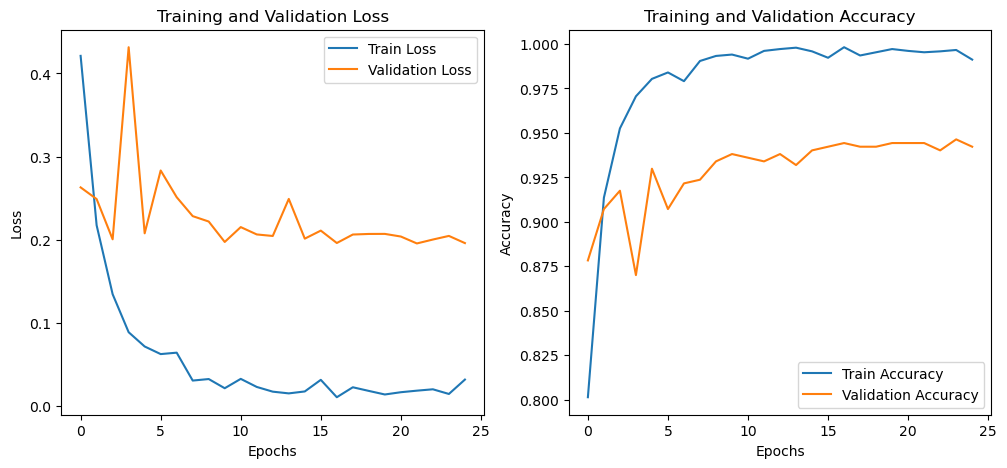

In [6]:
#Combine loaders into a dictionary
dataloaders = {
    'train': train_loader,
    'val': val_loader
}
#GPU Check
if DEVICE.type == 'cuda':
    print("Using GPU for training.")
else:
    print("Using CPU for training. Consider enabling CUDA for better performance.")
#Train the model
model = train_model(Resnet101, dataloaders, loss_function, optimizer, scheduler, num_epochs=25)

In [ ]:
# Save the trained model
torch.save(model.state_dict(), "resnet101_finetuned.pth")